# 06 MobileNetV2 Transfer Learning (with SMOTE Support)

## Objective
Train a lightweight, high-performance MobileNetV2 architecture with SMOTE class balancing:
- Phase 1: Feature extraction with frozen base weights
- Phase 2: Fine-tuning with progressive layer unfreezing
- Balanced training with SMOTE oversampling
- Comprehensive evaluation, confusion matrices, and model export

**Prerequisites:** `01_data_check.ipynb`, `02_dataset_visualization.ipynb`, `03_targeted_augmentation.ipynb`, `04_data_preprocessing.ipynb`, `05_cnn_baseline.ipynb`
**Next Step:** `07_offline_augmentation.ipynb`

## Step 1: Import Libraries

In [1]:
import sys
import os
import json

# Add utils to path
sys.path.insert(0, r"D:\cnn_model\utils")

# Import utilities
from data_utils import verify_dataset_structure
from model_utils import compute_class_weights_from_labels
from efficient_data_loader import create_train_val_test_datasets

# Import TensorFlow and Keras
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Set random seeds
np.random.seed(42)
tf.random.set_seed(42)

print("✓ Libraries imported successfully!")
print(f"TensorFlow version: {tf.__version__}")



✓ Libraries imported successfully!
TensorFlow version: 2.15.0


## Step 2: Load Preprocessed Data

In [3]:
import sys

print("Loading the existing SMOTE-balanced training data...\n")

# Path and configuration
# The original preprocessed data supplies validation/test files and labels.
data_base_path = r"D:\cnn_model\results\preprocessed_data_efficient"
# Reuse the already-generated ~10k-image SMOTE training set; do not regenerate it.
smote_base_path = r"D:\cnn_model\results\preprocessed_data_smote"
USE_SMOTE = True
BATCH_SIZE = 16

sys.path.insert(0, r"D:\cnn_model\utils")
from efficient_data_loader import create_train_val_test_datasets, get_class_weights, get_label_encoding

# Load the existing SMOTE-balanced dataset
train_dataset, val_dataset, test_dataset, metadata = create_train_val_test_datasets(
    base_path=data_base_path,
    batch_size=BATCH_SIZE,
    use_smote=USE_SMOTE,
    smote_base_path=smote_base_path
)

num_classes = metadata['num_classes']
label_encoding = metadata['label_encoding']
class_names = [label for label, _ in sorted(label_encoding.items(), key=lambda item: item[1])]
class_weights_dict = get_class_weights(data_base_path, use_smote=USE_SMOTE)

print(f"✓ Data pipeline ready! SMOTE Balanced: {metadata.get('smote_enabled', False)}")
print(f"  SMOTE training images used: {metadata['num_train']:,}")
print(f"  Validation samples: {metadata['num_val']}")
print(f"  Test samples: {metadata['num_test']}")
print(f"  Classes: {num_classes}")


Loading the existing SMOTE-balanced training data...


✓ Data pipeline ready! SMOTE Balanced: True
  SMOTE training images used: 10,240
  Validation samples: 860
  Test samples: 860
  Classes: 40


## Step 3: Training Configuration

In [4]:
# Training configuration
EPOCHS_PHASE1 = 20
EPOCHS_PHASE2 = 15  # Increased from 10 to 15 for better stabilization
BATCH_SIZE = 16  # Already defined above
TRAINABLE_LAYERS = 15  # Reduced from 30 to prevent overfitting
LEARNING_RATE_PHASE1 = 0.0001
LEARNING_RATE_PHASE2 = 5e-5  # Increased from 1e-6 to 5e-5 (50x higher!)
DENSE_UNITS = 128
DROPOUT_RATE = 0.5
MODEL_NAME = 'mobilenet_v2'

# Class Weighting Technique Configuration
# Options: 'class_weights_fit' (Keras fit class_weight parameter)
#          'sample_weights' (Dataset-level sample weights mapping)
#          'none' (No class weights)
CLASS_WEIGHT_TECHNIQUE = 'sample_weights'

print("Training Configuration:")
print(f"  Model: MobileNetV2 (Transfer Learning)")
print(f"  Phase 1 Epochs: {EPOCHS_PHASE1} (frozen base)")
print(f"  Phase 2 Epochs: {EPOCHS_PHASE2} (fine-tuned)")
print(f"  Batch Size: {BATCH_SIZE}")
print(f"  Input shape: (224, 224, 3)")
print(f"  Trainable layers (phase 2): {TRAINABLE_LAYERS}")
print(f"  Phase 1 LR: {LEARNING_RATE_PHASE1}")
print(f"  Phase 2 LR: {LEARNING_RATE_PHASE2} (INCREASED for stability)")
print(f"  Dense units: {DENSE_UNITS}")
print(f"  Dropout rate: {DROPOUT_RATE}")
print(f"  Class Weighting Technique: {CLASS_WEIGHT_TECHNIQUE}")
print(f"  Data source: Memory-efficient NPZ files (1 batch in RAM)\n")


Training Configuration:
  Model: MobileNetV2 (Transfer Learning)
  Phase 1 Epochs: 20 (frozen base)
  Phase 2 Epochs: 15 (fine-tuned)
  Batch Size: 16
  Input shape: (224, 224, 3)
  Trainable layers (phase 2): 15
  Phase 1 LR: 0.0001
  Phase 2 LR: 5e-05 (INCREASED for stability)
  Dense units: 128
  Dropout rate: 0.5
  Data source: Memory-efficient NPZ files (1 batch in RAM)



## Step 4: Build MobileNetV2 Model

In [5]:
print("\nBuilding MobileNetV2 model...\n")

# Load pretrained MobileNetV2 with frozen base
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze base model
base_model.trainable = False

# Build complete model with L2 regularization to prevent overfitting and push accuracy
model = tf.keras.Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(DENSE_UNITS, activation='relu', kernel_regularizer=keras.regularizers.l2(1e-4)),
    BatchNormalization(),
    Dropout(DROPOUT_RATE),
    Dense(64, activation='relu', kernel_regularizer=keras.regularizers.l2(1e-4)),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

# Compile for phase 1 (frozen base)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE_PHASE1),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("✓ MobileNetV2 model built successfully!")
print(f"  - Total layers: {len(model.layers)}")
print(f"  - Input shape: (224, 224, 3)")
print(f"  - Output classes: {num_classes}")
print(f"  - Base model trainable: False (Phase 1)\n")



Building MobileNetV2 model...



✓ MobileNetV2 model built successfully!
  - Total layers: 8
  - Input shape: (224, 224, 3)
  - Output classes: 40
  - Base model trainable: False (Phase 1)



## Step 5: Phase 1 - Train with Frozen Base

In [6]:
print("\n" + "="*70)
print("PHASE 1: Training with Frozen Base Layers")
print("="*70 + "\n")

# Setup callbacks for Phase 1
callbacks_phase1 = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        verbose=1
    )
]

# Calculate expected batches
num_train_batches = (train_count + BATCH_SIZE - 1) // BATCH_SIZE

print("Training on memory-efficient tf.data.Dataset:")
print(f"  - Each batch loads from disk (only 1 batch in RAM)")
print(f"  - Batch size: {BATCH_SIZE}")
print(f"  - Expected training batches: ~{num_train_batches}\n")

# Map dataset with sample weights if using 'sample_weights' technique
if CLASS_WEIGHT_TECHNIQUE == 'sample_weights':
    class_weight_values = tf.constant(
        [class_weight[i] for i in range(num_classes)],
        dtype=tf.float32
    )
    
    def add_sample_weights(images, labels):
        class_indices = tf.argmax(labels, axis=-1)
        sample_weights = tf.gather(class_weight_values, class_indices)
        return images, labels, sample_weights
        
    active_train_dataset = train_dataset.map(add_sample_weights, num_parallel_calls=tf.data.AUTOTUNE)
    print("✓ Using custom sample weights mapped in dataset")
else:
    active_train_dataset = train_dataset
    if CLASS_WEIGHT_TECHNIQUE == 'class_weights_fit':
        print("✓ Using Keras class_weight mapping during fit()")
    else:
        print("✓ Class weights DISABLED")

fit_kwargs = {
    'x': active_train_dataset,
    'validation_data': val_dataset,
    'epochs': EPOCHS_PHASE1,
    'callbacks': callbacks_phase1,
    'verbose': 1
}

if CLASS_WEIGHT_TECHNIQUE == 'class_weights_fit':
    fit_kwargs['class_weight'] = class_weight

history_phase1 = model.fit(**fit_kwargs)

print("\n✓ Phase 1 training completed!")



PHASE 1: Training with Frozen Base Layers

Training on memory-efficient tf.data.Dataset:
  - Each batch loads from disk (only 1 batch in RAM)
  - Batch size: 16
  - Expected training batches: ~430

Epoch 1/20


430/430 [==============================] - 133s 300ms/step - loss: 3.9881 - accuracy: 0.0594 - val_loss: 2.9381 - val_accuracy: 0.2744 - lr: 1.0000e-04
Epoch 2/20
430/430 [==============================] - 122s 283ms/step - loss: 3.1801 - accuracy: 0.1613 - val_loss: 2.4144 - val_accuracy: 0.4767 - lr: 1.0000e-04
Epoch 3/20
430/430 [==============================] - 119s 276ms/step - loss: 2.7486 - accuracy: 0.2673 - val_loss: 2.0589 - val_accuracy: 0.5849 - lr: 1.0000e-04
Epoch 4/20
430/430 [==============================] - 122s 284ms/step - loss: 2.4488 - accuracy: 0.3432 - val_loss: 1.7602 - val_accuracy: 0.6279 - lr: 1.0000e-04
Epoch 5/20
430/430 [==============================] - 137s 320ms/step - loss: 2.2135 - accuracy: 0.3975 - val_loss: 1.5442 - val_accuracy: 0.6721 -

## Step 6: Phase 2 - Fine-tune with Unfrozen Layers

In [7]:
print("\n" + "="*70)
print("PHASE 2: Fine-tuning with Progressive Layer Unfreezing")
print("="*70 + "\n")

# Unfreeze with PROGRESSIVE strategy (Solution 4) + Dropout Control (Solution 3)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Dropout

base_model = model.layers[0]

# STAGE 1: Unfreeze only 10 layers first for 5 epochs
print("STAGE 1: Unfrozing last 10 layers for 5 epochs (warming up)...\n")
for layer in base_model.layers[-10:]:
    layer.trainable = True

# Reduce dropout for stability during fine-tuning (Solution 3)
print("Reducing dropout rates for stability...")
for layer in model.layers:
    if isinstance(layer, Dropout):
        layer.rate = 0.3  # Reduce from 0.5 to 0.3
print("✓ Dropout reduced: 0.5 → 0.3\n")

# Recompile with HIGHER learning rate
model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE_PHASE2),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print(f"Learning rate: {LEARNING_RATE_PHASE2}\n")

# Callbacks for phase 2
callbacks_phase2 = [
    EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-8,
        verbose=1
    ),
    ModelCheckpoint(
        r'D:\cnn_model\models\mobilenet\best_model.h5',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=0
    )
]

os.makedirs(r'D:\cnn_model\models\mobilenet', exist_ok=True)

# Map dataset with sample weights if using 'sample_weights' technique
if CLASS_WEIGHT_TECHNIQUE == 'sample_weights':
    class_weight_values = tf.constant(
        [class_weight[i] for i in range(num_classes)],
        dtype=tf.float32
    )
    
    def add_sample_weights(images, labels):
        class_indices = tf.argmax(labels, axis=-1)
        sample_weights = tf.gather(class_weight_values, class_indices)
        return images, labels, sample_weights
        
    active_train_dataset = train_dataset.map(add_sample_weights, num_parallel_calls=tf.data.AUTOTUNE)
else:
    active_train_dataset = train_dataset

print("Training Stage 1 (10 unfrozen layers, 5 epochs)...\n")

fit_kwargs_phase2_s1 = {
    'x': active_train_dataset,
    'validation_data': val_dataset,
    'epochs': 5,
    'callbacks': callbacks_phase2,
    'verbose': 1
}

if CLASS_WEIGHT_TECHNIQUE == 'class_weights_fit':
    fit_kwargs_phase2_s1['class_weight'] = class_weight

history_phase2_s1 = model.fit(**fit_kwargs_phase2_s1)

print("\n" + "="*70)
print("STAGE 2: Unfrozing all remaining layers for final 10 epochs...")
print("="*70 + "\n")

# STAGE 2: Unfreeze ALL layers for 10 more epochs
for layer in base_model.layers[-TRAINABLE_LAYERS:]:
    layer.trainable = True

print(f"✓ Unfroze all {TRAINABLE_LAYERS} layers")
print(f"  Learning rate: {LEARNING_RATE_PHASE2}\n")

model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE_PHASE2),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Training Stage 2 (all layers unfrozen, 10 epochs)...\n")

fit_kwargs_phase2_s2 = {
    'x': active_train_dataset,
    'validation_data': val_dataset,
    'epochs': 10,
    'callbacks': callbacks_phase2,
    'verbose': 1
}

if CLASS_WEIGHT_TECHNIQUE == 'class_weights_fit':
    fit_kwargs_phase2_s2['class_weight'] = class_weight

history_phase2_s2 = model.fit(**fit_kwargs_phase2_s2)

# Combine stage histories
history_phase2 = type('obj', (object,), {
    'history': {
        key: history_phase2_s1.history[key] + history_phase2_s2.history[key]
        for key in history_phase2_s1.history.keys()
    }
})()

print("\n✓ Phase 2 (both stages) training completed!")



PHASE 2: Fine-tuning with Progressive Layer Unfreezing

STAGE 1: Unfrozing last 10 layers for 5 epochs (warming up)...

Reducing dropout rates for stability...
✓ Dropout reduced: 0.5 → 0.3

Learning rate: 5e-05

Training Stage 1 (10 unfrozen layers, 5 epochs)...



Epoch 1/5
    430/Unknown - 125s 282ms/step - loss: 1.4376 - accuracy: 0.5763

c:\Users\kansa\anaconda3\envs\cnn_model\lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


430/430 [==============================] - 147s 334ms/step - loss: 1.4376 - accuracy: 0.5763 - val_loss: 0.4488 - val_accuracy: 0.8674 - lr: 5.0000e-05
Epoch 2/5
430/430 [==============================] - 131s 304ms/step - loss: 1.2330 - accuracy: 0.6344 - val_loss: 0.4229 - val_accuracy: 0.8779 - lr: 5.0000e-05
Epoch 3/5
430/430 [==============================] - 131s 304ms/step - loss: 1.1006 - accuracy: 0.6698 - val_loss: 0.4347 - val_accuracy: 0.8767 - lr: 5.0000e-05
Epoch 4/5
430/430 [==============================] - 130s 303ms/step - loss: 1.0339 - accuracy: 0.6878 - val_loss: 0.4316 - val_accuracy: 0.8791 - lr: 5.0000e-05
Epoch 5/5
430/430 [==============================] - 130s 302ms/step - loss: 0.9813 - accuracy: 0.7054 - val_loss: 0.4358 - val_accuracy: 0.8872 - lr: 5.0000e-05

STAGE 2: Unfrozing all remaining layers for final 10 epochs...

✓ Unfroze all 15 layers
  Learning rate: 5e-05

Training Stage 2 (all layers unfrozen, 10 epochs)...

Epoch 1/10
430/430 [=============

## Step 7: Combine Training Histories

In [8]:
# Combine histories from both phases
combined_history = {}
for key in history_phase1.history.keys():
    combined_history[key] = history_phase1.history[key] + history_phase2.history[key]

print(f"✓ Combined training history from both phases")
print(f"  - Total epochs: {len(combined_history['loss'])}\n")

✓ Combined training history from both phases
  - Total epochs: 35



## Step 8: Plot Training History

Plotting training history...

✓ Saved: mobilenet_training_history.png


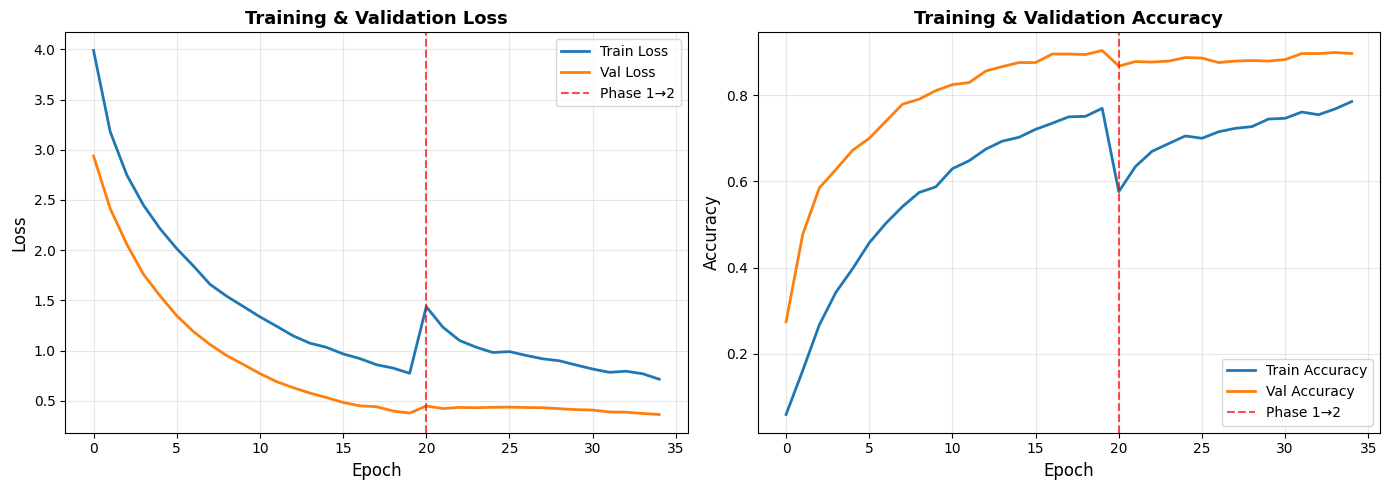

In [9]:
import matplotlib.pyplot as plt

# Create output directories
os.makedirs(r'D:\cnn_model\results\plots', exist_ok=True)
os.makedirs(r'D:\cnn_model\results\reports', exist_ok=True)

print("Plotting training history...\n")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
axes[0].plot(combined_history['loss'], label='Train Loss', linewidth=2)
axes[0].plot(combined_history['val_loss'], label='Val Loss', linewidth=2)
axes[0].axvline(x=len(history_phase1.history['loss']), color='red', linestyle='--', alpha=0.7, label='Phase 1→2')
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Loss', fontsize=12)
axes[0].set_title('Training & Validation Loss', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)

# Accuracy
axes[1].plot(combined_history['accuracy'], label='Train Accuracy', linewidth=2)
axes[1].plot(combined_history['val_accuracy'], label='Val Accuracy', linewidth=2)
axes[1].axvline(x=len(history_phase1.history['accuracy']), color='red', linestyle='--', alpha=0.7, label='Phase 1→2')
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Accuracy', fontsize=12)
axes[1].set_title('Training & Validation Accuracy', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(r'D:\cnn_model\results\plots\mobilenet_training_history.png', dpi=300, bbox_inches='tight')
print("✓ Saved: mobilenet_training_history.png")

## Step 9: Evaluate on Test Set

In [10]:
print("\nEvaluating model on test set...\n")

# Evaluate on test dataset
test_loss, test_accuracy = model.evaluate(test_dataset, verbose=0)

print("="*70)
print("MODEL EVALUATION RESULTS")
print("="*70)
print(f"\nTest Accuracy:  {test_accuracy:.4f}")
print(f"Test Loss:      {test_loss:.4f}\n")

# Get predictions for confusion matrix and detailed metrics
print("Computing detailed metrics...")
y_test_pred = model.predict(test_dataset, verbose=0)
y_test_pred_classes = np.argmax(y_test_pred, axis=1)
y_test_true_classes = np.argmax(y_test, axis=1)

from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

precision = precision_score(y_test_true_classes, y_test_pred_classes, average='weighted')
recall = recall_score(y_test_true_classes, y_test_pred_classes, average='weighted')
f1 = f1_score(y_test_true_classes, y_test_pred_classes, average='weighted')
cm = confusion_matrix(y_test_true_classes, y_test_pred_classes)

print(f"Precision:      {precision:.4f}")
print(f"Recall:         {recall:.4f}")
print(f"F1-Score:       {f1:.4f}\n")

metrics = {
    'accuracy': test_accuracy,
    'precision': precision,
    'recall': recall,
    'f1_score': f1,
    'loss': test_loss,
    'confusion_matrix': cm.tolist()
}


Evaluating model on test set...

MODEL EVALUATION RESULTS

Test Accuracy:  0.9012
Test Loss:      0.3556

Computing detailed metrics...
Precision:      0.9072
Recall:         0.9012
F1-Score:       0.8991



## Step 10: Plot Confusion Matrix

Plotting confusion matrix...

✓ Saved: mobilenet_confusion_matrix.png
✓ Saved: mobilenet_confusion_matrix_normalized.png


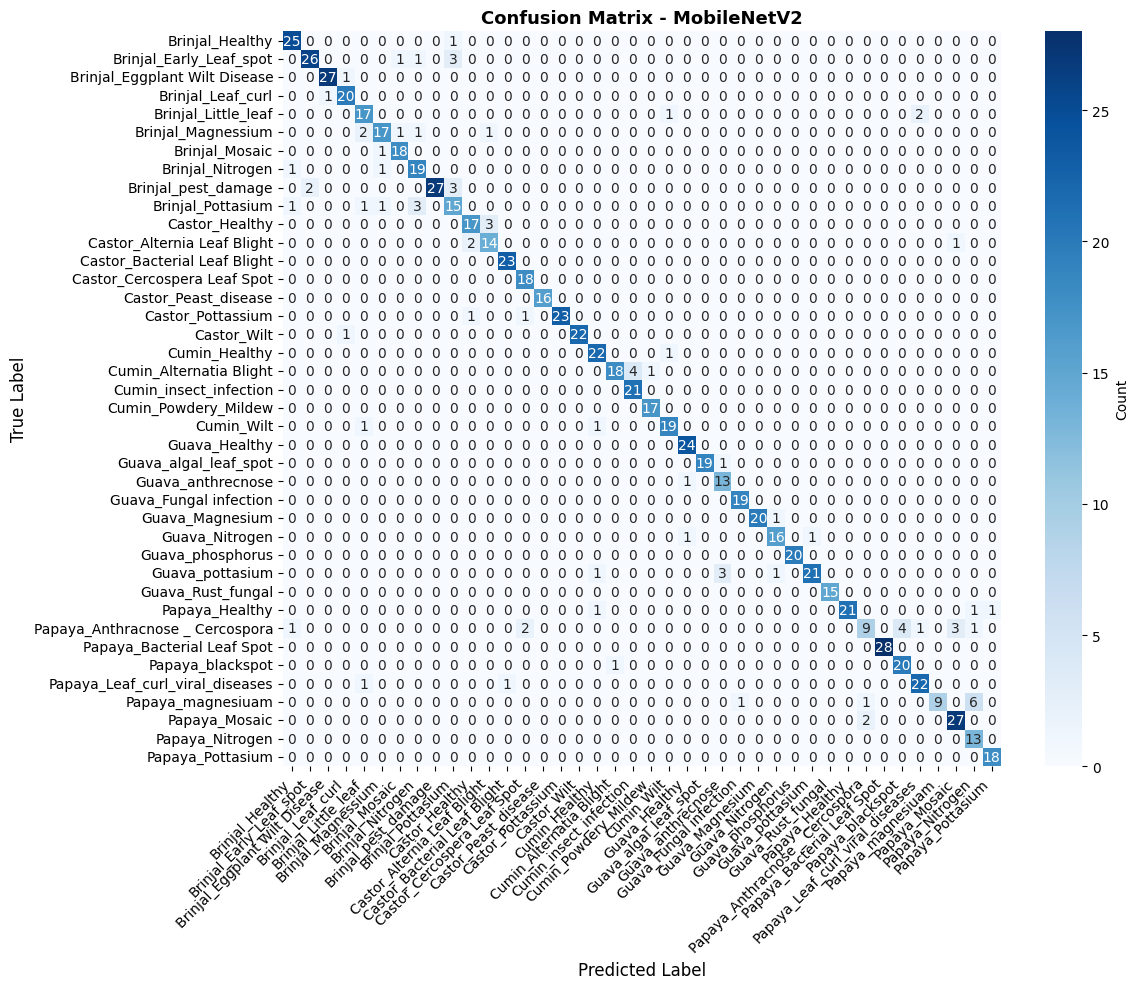

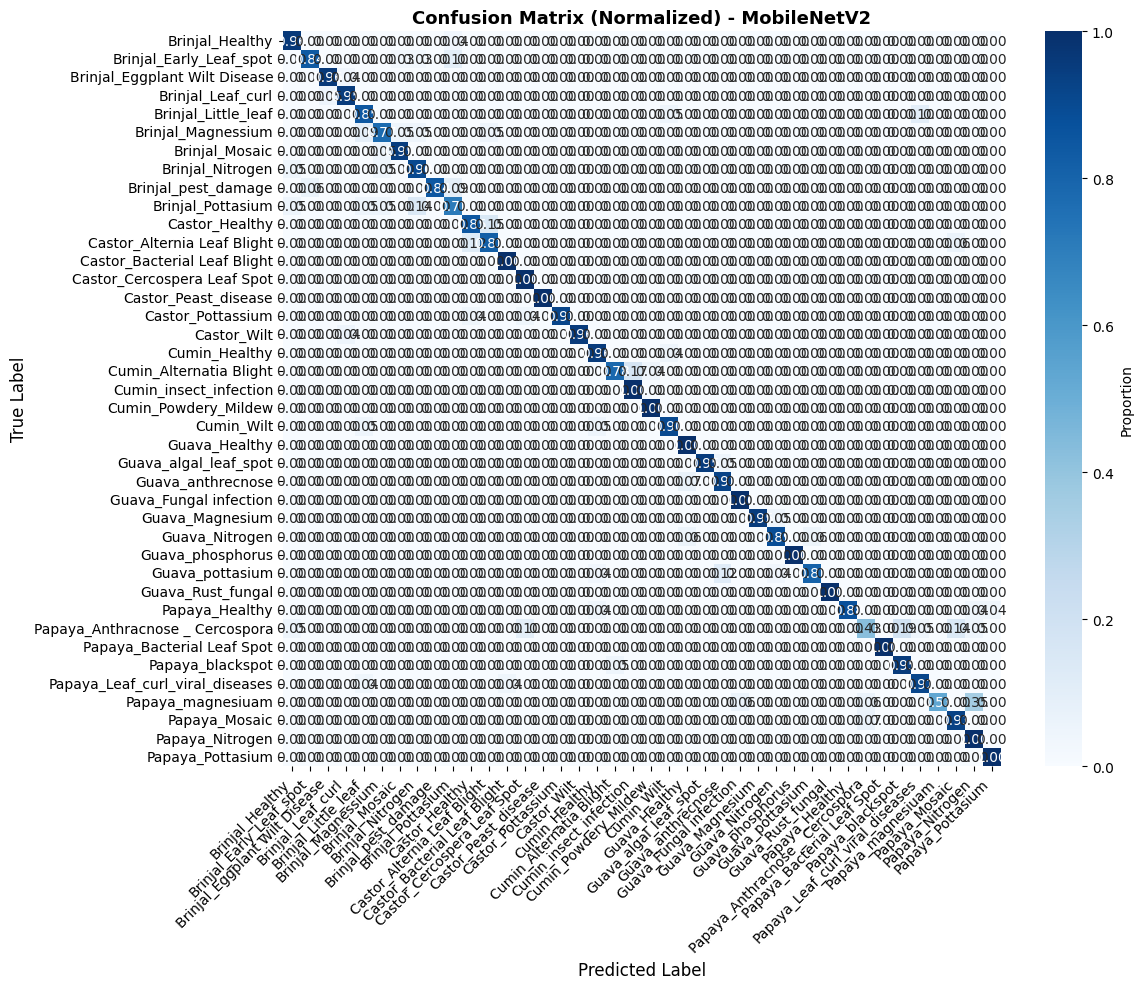

In [11]:
import seaborn as sns

print("Plotting confusion matrix...\n")

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax, cbar_kws={'label': 'Count'})
ax.set_xlabel('Predicted Label', fontsize=12)
ax.set_ylabel('True Label', fontsize=12)
ax.set_title('Confusion Matrix - MobileNetV2', fontsize=13, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(r'D:\cnn_model\results\plots\mobilenet_confusion_matrix.png', dpi=300, bbox_inches='tight')
print("✓ Saved: mobilenet_confusion_matrix.png")

# Normalized confusion matrix
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax, cbar_kws={'label': 'Proportion'})
ax.set_xlabel('Predicted Label', fontsize=12)
ax.set_ylabel('True Label', fontsize=12)
ax.set_title('Confusion Matrix (Normalized) - MobileNetV2', fontsize=13, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(r'D:\cnn_model\results\plots\mobilenet_confusion_matrix_normalized.png', dpi=300, bbox_inches='tight')
print("✓ Saved: mobilenet_confusion_matrix_normalized.png")

## Step 11: Plot Metrics Comparison


Plotting metrics comparison...

✓ Saved: mobilenet_metrics.png


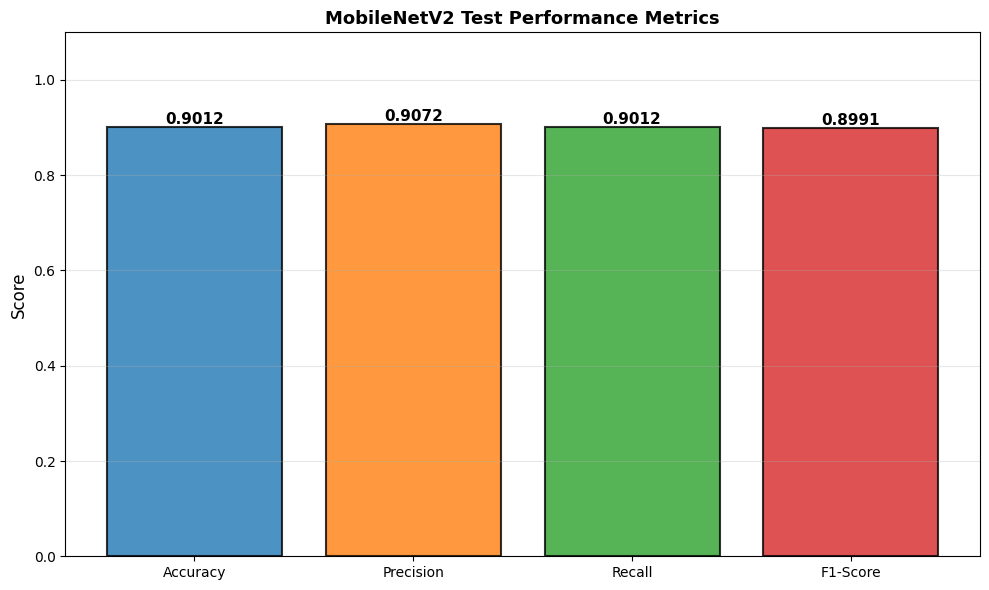

In [12]:
print("\nPlotting metrics comparison...\n")

metrics_values = {
    'Accuracy': metrics['accuracy'],
    'Precision': metrics['precision'],
    'Recall': metrics['recall'],
    'F1-Score': metrics['f1_score']
}

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(metrics_values.keys(), metrics_values.values(), color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'], alpha=0.8, edgecolor='black', linewidth=1.5)

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.4f}',
            ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_ylabel('Score', fontsize=12)
ax.set_title('MobileNetV2 Test Performance Metrics', fontsize=13, fontweight='bold')
ax.set_ylim([0, 1.1])
ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(r'D:\cnn_model\results\plots\mobilenet_metrics.png', dpi=300, bbox_inches='tight')
print("✓ Saved: mobilenet_metrics.png")

## Step 12: Save Trained Model

In [13]:
print("\nSaving model...\n")

model_dir = r'D:\cnn_model\models\mobilenet'
os.makedirs(model_dir, exist_ok=True)

model_path = f'{model_dir}/mobilenet_v2_final.h5'
model.save(model_path)

print(f"✓ Model saved to: {model_path}")
print(f"  File size: {os.path.getsize(model_path) / (1024**2):.2f} MB\n")


Saving model...



c:\Users\kansa\anaconda3\envs\cnn_model\lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


✓ Model saved to: D:\cnn_model\models\mobilenet/mobilenet_v2_final.h5
  File size: 10.97 MB



## Step 13: Save Metrics and Training History

In [14]:
print("Saving metrics and training history...\n")

reports_dir = r'D:\cnn_model\results\reports'
os.makedirs(reports_dir, exist_ok=True)

# Save metrics
metrics_path = f'{reports_dir}/mobilenet_metrics.json'
metrics_save = {
    'accuracy': float(metrics['accuracy']),
    'precision': float(metrics['precision']),
    'recall': float(metrics['recall']),
    'f1_score': float(metrics['f1_score']),
    'loss': float(metrics['loss'])
}

with open(metrics_path, 'w') as f:
    json.dump(metrics_save, f, indent=4)

print(f"✓ Metrics saved to: {metrics_path}")

# Save history
history_path = f'{reports_dir}/mobilenet_history.json'
history_save = {k: [float(v) for v in vals] for k, vals in combined_history.items()}

with open(history_path, 'w') as f:
    json.dump(history_save, f, indent=4)

print(f"✓ History saved to: {history_path}\n")

Saving metrics and training history...

✓ Metrics saved to: D:\cnn_model\results\reports/mobilenet_metrics.json
✓ History saved to: D:\cnn_model\results\reports/mobilenet_history.json



## Step 14: Final Summary

In [16]:
print("\n" + "="*70)
print("✓ MOBILENET V2 TRAINING COMPLETE")
print("="*70)

print(f"\n📊 Results Summary:")
print(f"  Model: MobileNetV2 (Transfer Learning)")
print(f"  Test Accuracy: {metrics['accuracy']:.4f}")
print(f"  Test Precision: {metrics['precision']:.4f}")
print(f"  Test Recall: {metrics['recall']:.4f}")
print(f"  Test F1-Score: {metrics['f1_score']:.4f}")

print(f"\n📁 Data Summary:")
print(f"  Train images: {train_count}")
print(f"  Val images: {val_count}")
print(f"  Test images: {test_count}")
print(f"  Total classes: {num_classes}")
print(f"  Data loading: Memory-efficient (NPZ files on disk)")

print(f"\n⚙️  Training Summary:")
print(f"  Phase 1: {EPOCHS_PHASE1} epochs (frozen base)")
print(f"  Phase 2: {EPOCHS_PHASE2} epochs (unfrozen layers)")
print(f"  Batch size: {BATCH_SIZE}")
print(f"  Input shape: (224, 224, 3)")

print(f"\n💾 Files Saved:")
model_file = r'D:\cnn_model\models\mobilenet\mobilenet_v2_final.h5'
metrics_file = r'D:\cnn_model\results\reports\mobilenet_metrics.json'
history_file = r'D:\cnn_model\results\reports\mobilenet_history.json'
plots_file = r'D:\cnn_model\results\plots\mobilenet_*.png'
print(f"  - Model: {model_file}")
print(f"  - Metrics: {metrics_file}")
print(f"  - History: {history_file}")
print(f"  - Plots: {plots_file}")

print(f"\n→ Next Step: Run 08_model_evaluation.ipynb for detailed analysis")


✓ MOBILENET V2 TRAINING COMPLETE

📊 Results Summary:
  Model: MobileNetV2 (Transfer Learning)
  Test Accuracy: 0.9012
  Test Precision: 0.9072
  Test Recall: 0.9012
  Test F1-Score: 0.8991

📁 Data Summary:
  Train images: 6880
  Val images: 860
  Test images: 860
  Total classes: 40
  Data loading: Memory-efficient (NPZ files on disk)

⚙️  Training Summary:
  Phase 1: 20 epochs (frozen base)
  Phase 2: 15 epochs (unfrozen layers)
  Batch size: 16
  Input shape: (224, 224, 3)

💾 Files Saved:
  - Model: D:\cnn_model\models\mobilenet\mobilenet_v2_final.h5
  - Metrics: D:\cnn_model\results\reports\mobilenet_metrics.json
  - History: D:\cnn_model\results\reports\mobilenet_history.json
  - Plots: D:\cnn_model\results\plots\mobilenet_*.png

→ Next Step: Run 06_model_evaluation.ipynb for detailed analysis
